# 04 Kje in koga zrak najbolj prizadene (odločevalci)

**Namen:** iz registrov in meritev sestaviti karto, ki pokaže, v katerih četrtnih skupnostih (ČS) Ljubljane se stikajo trije dejavniki: veliko individualnih kurišč, nizka lega v kotlini (hladno jezero ob inverziji) in visoke izmerjene zimske koncentracije. Taka karta usmerja ukrepe in komunikacijo, ni pa meritev po soseskah.

**Ciljna skupina:** mestni načrtovalci in odločevalci (namen izziva: *razložiti*, kje in koga).

**Vhodi:** kataster nepremičnin (stavbe, leto izgradnje, stanovanja, priključek na plin), ZKGJI (vročevod, plinovod), EviDim (število kurilnih naprav po občini), četrtne skupnosti MOL, DEM (višina nad dnom kotline), uradne postaje ARSO in umerjeni občanski senzorji.

**Kaj je kaj:** register (stavbe, omrežja, EviDim) → **stanje registra**; DEM → **model površja**; postaje ARSO → **meritev**; umerjeni senzorji → **ocena**; število kurišč po ČS in končni indeks → **ocena z eksplicitnimi predpostavkami** (vsaka je v svoji celici in jo lahko spremenite).

Rezultat tabele po ČS se shrani v `cs_kazalniki.csv`, ki ga uporablja zvezek 07 (scenariji ukrepov).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys; sys.path.insert(0, ".")
from paket import *
import geopandas as gpd, pyogrio, rasterio
from rasterio.mask import mask
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 180)

## 1. Četrtne skupnosti in stavbe v Ljubljani (register)

Vzamemo samo stavbe v občini Ljubljana (061) in jih po centroidu pripišemo četrtni skupnosti. Zanimajo nas **stanovanjske** stavbe (vsaj en del z rabo stanovanje).

In [2]:
cs = gpd.read_file(P/"04_prostor/mol_cetrtne_skupnosti.geojson").to_crs(3794)
cs["cs_ime"] = cs.cs_ime.str.replace("ČETRTNA SKUPNOST ", "").str.title()
cs["povrsina_km2"] = cs.geometry.area / 1e6

st = pyogrio.read_dataframe(P/"04_prostor/kn_stavbe.gpkg", layer="stavbe_tlorisi", where="obcina_sifra='061'",
        columns=["eid_stavba","stanovanjska","stevilo_stanovanj","leto_izgradnje","plin","stevilo_etaz"])
st["geometry"] = st.geometry.centroid
st = st.sjoin(cs[["cs_id","cs_ime","geometry"]], how="inner", predicate="within").drop(columns="index_right")
res = st[st.stanovanjska == True].copy()
print(f"stavb v MOL: {len(st):,}, od tega stanovanjskih: {len(res):,}; ČS: {len(cs)}")
res.head(3)

stavb v MOL: 69,901, od tega stanovanjskih: 38,653; ČS: 17


,eid_stavba,stevilo_etaz,stevilo_stanovanj,plin,leto_izgradnje,stanovanjska,geometry,cs_id,cs_ime
0,100201000000243274,2.0,2.0,2.0,2025.0,True,POINT (460043.17 96113.998),33,Rudnik
2,100201000000010111,2.0,1.0,2.0,2022.0,True,POINT (462273.867 99183.666),33,Rudnik
3,100201000000101209,3.0,2.0,2.0,2023.0,True,POINT (456444.155 107861.348),35,Šentvid


## 2. Bližina vročevoda in plinovoda (register ZKGJI)

Stavba, ki je **do 50 m od vročevoda**, je zelo verjetno priključena na daljinsko ogrevanje. Stavba **do 30 m od plinovoda** ima plin na voljo, kar pa ne pomeni, da ga uporablja. Polje `plin` v katastru je izpolnjeno le pri ~15 % stavb, zato ga uporabimo samo kot dodatni znak.

In [3]:
vr = pyogrio.read_dataframe(P/"04_prostor/zkgji_vrocevod.gpkg", layer="linije", columns=["vrsta_objekta"])
vr = vr[vr.vrsta_objekta.isin(["Vročevod", "Toplovod"])]
pl = pyogrio.read_dataframe(P/"04_prostor/zkgji_plinovod.gpkg", layer="linije", columns=["vrsta_objekta"])
pl = pl[pl.vrsta_objekta == "Plinovod"]

res = res.sjoin_nearest(vr[["geometry"]], how="left", max_distance=50, distance_col="d_vrocevod").drop(columns="index_right")
res = res[~res.index.duplicated()]
res = res.sjoin_nearest(pl[["geometry"]], how="left", max_distance=30, distance_col="d_plinovod").drop(columns="index_right")
res = res[~res.index.duplicated()]
res["ob_vrocevodu"] = res.d_vrocevod.notna()
res["ob_plinovodu"] = res.d_plinovod.notna()
res["plin_da"] = res.plin == 1
print("stanovanjske stavbe:", len(res),
      "| ob vročevodu:", res.ob_vrocevodu.sum(), "| ob plinovodu:", res.ob_plinovodu.sum(),
      "| plin = da v KN:", res.plin_da.sum(), "| brez obeh omrežij:", (~res.ob_vrocevodu & ~res.ob_plinovodu).sum())

stanovanjske stavbe: 38653 | ob vročevodu: 5423 | ob plinovodu: 30683 | plin = da v KN: 2836 | brez obeh omrežij: 6021


## 3. Ocena števila kurišč na trda goriva po ČS (ocena)

EviDim pove, koliko malih kurilnih naprav je v občini po gorivu, ne pa kje. Za Ljubljano: **trdno gorivo 14.141** naprav (+ 218 kombiniranih), tekoče 11.679, plinasto 49.257. Prostorsko jih razporedimo po stanovanjskih stavbah z **utežmi** (predpostavka, spremenite jo v tej celici):

| stavba | utež |
|---|---|
| ob vročevodu | 0,05 (redke peči kot dopolnilo) |
| ob plinovodu ali plin = da, brez vročevoda | 0,35 (plin na voljo, a kamini in peči so pogosti) |
| brez obeh omrežij | 1,0 |

Uteži nato lestvičimo, da je vsota za MOL enaka številu naprav na trda goriva iz EviDim. To je **ocena**: število na ČS je pravilno le po redu velikosti.

In [4]:
ev = pd.read_csv(P/"04_prostor/evidim_kurilne_naprave_obcine.csv", dtype={"obcina_sifra": str})
lj = ev[(ev.obcina_sifra == "061") & (ev.dimenzija == "vrsta_goriva")].set_index("kategorija").stevilo_naprav
TRDNO_MOL = int(lj["TRDNO"] + lj["TEKOČE IN TRDNO"] + lj["PLINASTO IN TRDNO"])

UTEZ = {"ob_vrocevodu": 0.05, "plin_na_voljo": 0.35, "brez_omrezij": 1.0}     # predpostavka
res["utez"] = np.where(res.ob_vrocevodu, UTEZ["ob_vrocevodu"],
              np.where(res.ob_plinovodu | res.plin_da, UTEZ["plin_na_voljo"], UTEZ["brez_omrezij"]))
faktor = TRDNO_MOL / res.utez.sum()
res["kurisca_ocena"] = res.utez * faktor
print(f"EviDim MOL, naprave na trda goriva: {TRDNO_MOL:,}; faktor lestvičenja: {faktor:.2f}")

k = res.groupby("cs_ime").agg(
    stavbe_stan=("eid_stavba", "size"), stanovanja=("stevilo_stanovanj", "sum"),
    delez_pred_1980=("leto_izgradnje", lambda s: ((s > 0) & (s < 1980)).mean()),
    delez_ob_vrocevodu=("ob_vrocevodu", "mean"), delez_ob_plinovodu=("ob_plinovodu", "mean"),
    stavbe_brez_omrezij=("utez", lambda s: (s == 1.0).sum()),
    kurisca_trda_ocena=("kurisca_ocena", "sum"))
k = cs.set_index("cs_ime")[["cs_id", "povrsina_km2"]].join(k)
k["kurisca_na_km2"] = k.kurisca_trda_ocena / k.povrsina_km2
k.sort_values("kurisca_trda_ocena", ascending=False).round(2)

EviDim MOL, naprave na trda goriva: 14,366; faktor lestvičenja: 0.91


,cs_id,povrsina_km2,stavbe_stan,stanovanja,delez_pred_1980,delez_ob_vrocevodu,delez_ob_plinovodu,stavbe_brez_omrezij,kurisca_trda_ocena,kurisca_na_km2
cs_ime,,,,,,,,,,
Sostro,34,88.57,2367,2656.0,0.43,0.00,0.27,1733,1781.91,20.12
Polje,31,22.10,4185,7533.0,0.71,0.00,0.86,577,1676.99,75.87
Rudnik,33,25.48,3403,5950.0,0.47,0.00,0.82,618,1451.80,56.99
Šentvid,35,15.83,3121,5736.0,0.72,0.02,0.83,509,1281.40,80.93
Trnovo,37,7.18,2928,6956.0,0.57,0.02,0.92,239,1059.04,147.56
Rožnik,32,8.35,2765,7587.0,0.74,0.00,0.94,139,964.47,115.44
Šmarna Gora,36,14.43,1481,1961.0,0.48,0.00,0.47,787,938.76,65.06
Črnuče,27,18.10,2253,4968.0,0.58,0.00,0.91,176,823.05,45.47
Vič,38,14.38,2115,6775.0,0.65,0.08,0.86,271,789.09,54.87


## 4. Lega v kotlini (model površja)

Mediana višine nad dnom kotline (278 m) po ČS iz Copernicus DEM. Ob zimski inverziji je najbolj onesnažen zrak v spodnjih nekaj deset metrih; ČS, ki ležijo nizko, so bolj izpostavljene. Sostro in Šmarna gora segajo v hribe, zato je njihova mediana visoka, čeprav imajo naselja ob vznožju.

In [5]:
with rasterio.open(P/"04_prostor/dem_lj_kotlina_30m_visina_nad_dnom.tif") as r:
    cs4 = cs.to_crs(r.crs)
    h = []
    for geom in cs4.geometry:
        a = mask(r, [geom.__geo_interface__], crop=True, nodata=r.nodata)[0][0]
        a = a[a != r.nodata]
        h.append((float(np.median(a)), float((a < 30).mean())))
cs["h_nad_dnom_mediana"] = [x[0] for x in h]
cs["delez_pod_30m"] = [x[1] for x in h]
k = k.join(cs.set_index("cs_ime")[["h_nad_dnom_mediana", "delez_pod_30m"]])
k[["h_nad_dnom_mediana", "delez_pod_30m"]].sort_values("h_nad_dnom_mediana").round(2).T

cs_ime,Polje,Moste,Rudnik,Jarše,Trnovo,Črnuče,Vič,Posavje,Bežigrad,Center,Rožnik,Šiška,Šentvid,Golovec,Dravlje,Šmarna Gora,Sostro
h_nad_dnom_mediana,-1.10,8.49,9.98,10.61,12.58,14.98,18.10,18.93,21.59,22.13,29.00,29.69,40.39,45.72,57.79,67.05,213.62
delez_pod_30m,0.77,1.00,0.85,1.00,1.00,0.69,0.94,0.90,0.97,0.73,0.52,0.52,0.22,0.44,0.10,0.23,0.08


## 5. Izmerjene zimske koncentracije (meritev in ocena)

Za vsako ČS vzamemo **najbližji vir** k njenemu središču: postajo ARSO (meritev) ali zanesljiv umerjen občanski senzor (ocena), in njegovo povprečje PM2.5 za zimo 2025/26 (nov–mar). Mreža je redka (3 postaje + 10 naprav), zato je to le približek; razdalja do vira je zapisana.

In [6]:
pm = nalozi_arso()
pmz = zima(pm[(pm.time_utc >= "2025-11-01") & (pm.time_utc < "2026-04-01")])
viri = [dict(vir=f"ARSO {POSTAJE[c]['ime']}", vrsta="meritev", lat=POSTAJE[c]["lat"], lon=POSTAJE[c]["lon"],
             pm25=pmz[pmz.station_code == c].pm25.mean()) for c in POSTAJE]
sen = nalozi_senzorje_umerjene()
senz = sen[(sen.time_utc >= "2025-11-01") & (sen.time_utc < "2026-04-01")]
for (src, sid), g in senz.groupby(["source", "sensor_id"]):
    if g.pm25_cal.notna().sum() >= 1000:
        viri.append(dict(vir=f"{src} {sid}", vrsta="ocena (umerjen senzor)", lat=g.lat.iloc[0], lon=g.lon.iloc[0], pm25=g.pm25_cal.mean()))
viri = gpd.GeoDataFrame(pd.DataFrame(viri), geometry=gpd.points_from_xy([v["lon"] for v in viri], [v["lat"] for v in viri]), crs=4326).to_crs(3794)

sred = cs.copy(); sred["geometry"] = cs.geometry.centroid
bl = sred.sjoin_nearest(viri[["vir", "vrsta", "pm25", "geometry"]], how="left", distance_col="vir_km")
bl = bl[~bl.index.duplicated()]
bl["vir_km"] = bl.vir_km / 1000
k = k.join(bl.set_index("cs_ime")[["vir", "vrsta", "pm25", "vir_km"]].rename(columns={"pm25": "pm25_zima_2025_26"}))
print("zimsko povprečje PM2.5 po virih (µg/m³):"); print(viri[["vir", "vrsta", "pm25"]].round(1).to_string(index=False))
k[["vir", "vrsta", "pm25_zima_2025_26", "vir_km"]].round(1)

zimsko povprečje PM2.5 po virih (µg/m³):
                   vir                  vrsta  pm25
      ARSO LJ Bežigrad                meritev  18.7
      ARSO LJ Celovška                meritev  17.9
           ARSO LJ Vič                meritev  18.4
       purpleair 96479 ocena (umerjen senzor)  19.9
      purpleair 126385 ocena (umerjen senzor)  15.9
 sensor_community 9821 ocena (umerjen senzor)  19.7
sensor_community 21901 ocena (umerjen senzor)  22.9
sensor_community 44606 ocena (umerjen senzor)  17.0
sensor_community 56181 ocena (umerjen senzor)  19.2
sensor_community 64688 ocena (umerjen senzor)  18.8
sensor_community 67867 ocena (umerjen senzor)  15.1
sensor_community 74650 ocena (umerjen senzor)  20.5


,vir,vrsta,pm25_zima_2025_26,vir_km
cs_ime,,,,
Center,ARSO LJ Bežigrad,meritev,18.7,1.6
Črnuče,ARSO LJ Bežigrad,meritev,18.7,4.9
Golovec,sensor_community 56181,ocena (umerjen senzor),19.2,1.8
Jarše,sensor_community 56181,ocena (umerjen senzor),19.2,2.2
Moste,sensor_community 56181,ocena (umerjen senzor),19.2,0.7
Polje,purpleair 96479,ocena (umerjen senzor),19.9,2.4
Rožnik,purpleair 126385,ocena (umerjen senzor),15.9,0.9
Rudnik,ARSO LJ Vič,meritev,18.4,3.5
Sostro,sensor_community 21901,ocena (umerjen senzor),22.9,4.4


## 6. Sestavljen indeks izpostavljenosti (ocena)

Štiri komponente, vsaka normirana na 0–1 med ČS, in uteži, ki jih **spremenite v tej celici**:

- gostota ocenjenih kurišč na trda goriva (kurišča/km²),
- nizka lega: delež površine ČS pod 30 m nad dnom kotline,
- izmerjena/ocenjena zimska PM2.5 najbližjega vira,
- delež stavb, zgrajenih pred 1980 (starejši kotli in peči, slabša izolacija).

Indeks ne pove, koliko ljudi je prizadetih; za to manjkajo podatki o prebivalcih po ČS (glej razdelek 10). Kot približek je dodana utež s številom stanovanj.

In [7]:
UTEZI = {"kurisca_na_km2": 0.35, "delez_pod_30m": 0.25, "pm25_zima_2025_26": 0.25, "delez_pred_1980": 0.15}   # predpostavka
def norm(s): return (s - s.min()) / (s.max() - s.min())
for c in UTEZI: k[f"n_{c}"] = norm(k[c])
k["indeks"] = sum(w * k[f"n_{c}"] for c, w in UTEZI.items())
k["indeks_x_stanovanja"] = k.indeks * k.stanovanja / k.stanovanja.sum() * len(k)
tab = k.sort_values("indeks", ascending=False)[["indeks", "indeks_x_stanovanja", "kurisca_trda_ocena", "kurisca_na_km2", "delez_pod_30m", "pm25_zima_2025_26", "delez_pred_1980", "stanovanja"]]
tab.round(2)

,indeks,indeks_x_stanovanja,kurisca_trda_ocena,kurisca_na_km2,delez_pod_30m,pm25_zima_2025_26,delez_pred_1980,stanovanja
cs_ime,,,,,,,,
Trnovo,0.76,0.66,1059.04,147.56,1.00,18.37,0.57,6956.0
Moste,0.70,0.83,286.17,84.19,1.00,19.24,0.86,9327.0
Bežigrad,0.62,1.37,547.36,75.63,0.97,18.65,0.75,17539.0
Jarše,0.61,0.51,542.26,59.83,1.00,19.24,0.78,6528.0
Polje,0.59,0.56,1676.99,75.87,0.77,19.86,0.71,7533.0
Vič,0.55,0.47,789.09,54.87,0.94,19.66,0.65,6775.0
Šiška,0.52,1.25,619.78,84.16,0.52,17.92,0.81,19146.0
Rožnik,0.51,0.49,964.47,115.44,0.52,15.94,0.74,7587.0
Center,0.51,0.98,227.92,44.93,0.73,18.65,0.86,15347.0


## 7. Preverjanje z emisijami ARSO (inventar) in modelom GRAL (model)

ARSO je za hekaton pripravil dva neodvisna vira, s katerima **oceno kurišč iz razdelka 3 preverimo**:

- **Emisijski inventar** `04_prostor/emisije/emisije_po_cs.csv`: letne emisije PM10 malih kurišč po ČS (kg/leto), iz emisij po stavbah, "zabrisanih" po območjih. To je inventar (ocena ARSO iz registrov in rabe goriv), ne meritev.
- **Model GRAL** `02_modeli/gral/gral_kurisca_cs_urno.csv`: urni **prispevek malih kurišč h koncentraciji PM10** (µg/m³) na mreži 15 m, povprečen po ČS, za leto 2021 (meteorologija 2021, emisije iz inventarja; `time_utc` omogoča združitev z meritvami 2021). Brez ozadja in drugih virov, zato ni primerljiv z meritvami, je pa prava prostorska slika, kje kurišča največ prispevajo. Vzhodni del MOL je zunaj mreže (Sostro 23 % pokritosti, Polje 75 %).

Če se razvrstitev ČS po naši oceni, po inventarju in po modelu ujema, je ocena iz registrov uporabna; kjer se razhaja, velja inventar in model.

In [8]:
em = pd.read_csv(P/"04_prostor/emisije/emisije_po_cs.csv")
em["cs_ime"] = em.cs_ime.str.replace("ČETRTNA SKUPNOST ", "").str.title()
em = em[em.cs_ime != "Mol Skupaj"].set_index("cs_ime")
k["emisije_kurisca_kg_leto"] = em.kurisca_pm10_kg_leto
k["emisije_kg_na_km2"] = k.emisije_kurisca_kg_leto / k.povrsina_km2

g = pd.read_csv(P/"02_modeli/gral/gral_kurisca_cs_urno.csv", comment="#")
with open(P/"02_modeli/gral/gral_kurisca_cs_urno.csv", encoding="utf-8") as f:
    f.readline(); pokr = f.readline().split(":", 1)[1]
pokr = {a.strip().replace("ČETRTNA SKUPNOST ", "").title(): float(b) for a, b in (x.strip().rsplit(" ", 1) for x in pokr.split(","))}
g.columns = [c.replace("ČETRTNA SKUPNOST ", "").title() if c.startswith("ČETRTNA") else c for c in g.columns]
cs_cols = [c for c in g.columns if c in k.index]
kur = g[g.mesec.isin([10, 11, 12, 1, 2, 3, 4, 5])]                       # kurilna sezona 2021 (jan–maj, okt–dec)
k["gral_pm10_kurilna"] = kur[cs_cols].mean()                              # µg/m³, prispevek kurišč, povprečje ČS
k["gral_pm10_januar"] = g[g.mesec == 1][cs_cols].mean()
k["gral_pokritost"] = pd.Series(pokr)
k.loc[k.gral_pokritost < 0.5, ["gral_pm10_kurilna", "gral_pm10_januar"]] = np.nan   # Sostro: premalo mreže

prim = k[["kurisca_trda_ocena", "kurisca_na_km2", "emisije_kurisca_kg_leto", "emisije_kg_na_km2", "gral_pm10_kurilna", "gral_pm10_januar", "gral_pokritost"]]
rk = prim[["kurisca_na_km2", "emisije_kg_na_km2", "gral_pm10_kurilna"]].rank(ascending=False)
print("Spearmanova korelacija razvrstitev ČS: ocena proti inventarju %.2f, ocena proti GRAL %.2f, inventar proti GRAL %.2f"
      % (rk.kurisca_na_km2.corr(rk.emisije_kg_na_km2), rk.kurisca_na_km2.corr(rk.gral_pm10_kurilna), rk.emisije_kg_na_km2.corr(rk.gral_pm10_kurilna)))
print(f"MOL: inventar {k.emisije_kurisca_kg_leto.sum()/1000:.1f} t PM10/leto iz kurišč; GRAL prispevek kurišč v kurilni sezoni po ČS {k.gral_pm10_kurilna.min():.1f}–{k.gral_pm10_kurilna.max():.1f} µg/m³")
prim.sort_values("gral_pm10_kurilna", ascending=False).round(2)

Spearmanova korelacija razvrstitev ČS: ocena proti inventarju 0.60, ocena proti GRAL 0.36, inventar proti GRAL 0.06
MOL: inventar 127.4 t PM10/leto iz kurišč; GRAL prispevek kurišč v kurilni sezoni po ČS 1.6–7.4 µg/m³


,kurisca_trda_ocena,kurisca_na_km2,emisije_kurisca_kg_leto,emisije_kg_na_km2,gral_pm10_kurilna,gral_pm10_januar,gral_pokritost
cs_ime,,,,,,,
Center,227.92,44.93,1867.12,368.04,7.42,21.38,1.00
Trnovo,1059.04,147.56,11448.51,1595.21,7.27,19.07,1.00
Moste,286.17,84.19,1332.47,391.99,5.11,15.47,1.00
Bežigrad,547.36,75.63,4182.16,577.84,5.08,14.94,1.00
Rožnik,964.47,115.44,3944.12,472.07,4.70,12.12,1.00
Šiška,619.78,84.16,4743.03,644.09,4.69,12.78,1.00
Vič,789.09,54.87,7709.83,536.09,3.95,9.85,1.00
Jarše,542.26,59.83,7746.68,854.69,3.68,11.14,1.00
Golovec,315.02,38.11,3483.64,421.41,3.52,10.32,1.00


Inventar meri **emisije** (kaj gre iz dimnikov), GRAL pa **koncentracijo** (kaj ljudje dihajo), ki je poleg emisij odvisna od lege, prevetrenosti in gostote pozidave. ČS z razpršenimi kurišči v kotlini (Sostro, Šmarna gora) ima lahko velike emisije in zmeren prispevek h koncentraciji, strnjena soseska z manj kurišči pa višje vrednosti. Prav to razliko potrebuje odločevalec: emisije povedo, **kje ukrepati**, koncentracije pa, **kje so ljudje najbolj izpostavljeni**.

## 8. Indeks z GRAL namesto ocene kurišč

Isti indeks, le da komponento "gostota ocenjenih kurišč" zamenja prispevek kurišč iz modela GRAL (kurilna sezona). Za Sostro, kjer mreža pokrije manj kot polovico ČS, ostane ocena.

In [9]:
k["gral_ali_ocena"] = k.gral_pm10_kurilna.fillna(k.gral_pm10_kurilna.mean() * k.kurisca_na_km2 / k.kurisca_na_km2.mean())
UTEZI_GRAL = {"gral_ali_ocena": 0.35, "delez_pod_30m": 0.25, "pm25_zima_2025_26": 0.25, "delez_pred_1980": 0.15}
k["n_gral_ali_ocena"] = norm(k.gral_ali_ocena)
k["indeks_gral"] = sum(w * k[f"n_{c}"] for c, w in UTEZI_GRAL.items())
prim2 = k[["indeks", "indeks_gral"]].copy()
prim2["mesto_ocena"] = prim2.indeks.rank(ascending=False).astype(int); prim2["mesto_gral"] = prim2.indeks_gral.rank(ascending=False).astype(int)
prim2.sort_values("indeks_gral", ascending=False).round(2)

,indeks,indeks_gral,mesto_ocena,mesto_gral
cs_ime,,,,
Center,0.51,0.79,9,1
Moste,0.70,0.75,2,2
Trnovo,0.76,0.75,1,3
Bežigrad,0.62,0.69,3,4
Jarše,0.61,0.65,4,5
Vič,0.55,0.61,6,6
Šiška,0.52,0.54,7,7
Polje,0.59,0.53,5,8
Rožnik,0.51,0.45,8,9


## 9. Karta

Levo: indeks izpostavljenosti (ocena); točke: postaje ARSO (meritev) in občanski senzorji (ocena); številka: ocenjeno število kurišč na trda goriva. Desno: prispevek kurišč h PM10 v januarju po modelu GRAL (15 m, prikazano na 60 m), isti obrisi ČS.

Barva: indeks izpostavljenosti (ocena). Točke: postaje ARSO (meritev) in občanski senzorji (ocena). Številka: ocenjeno število kurišč na trda goriva.

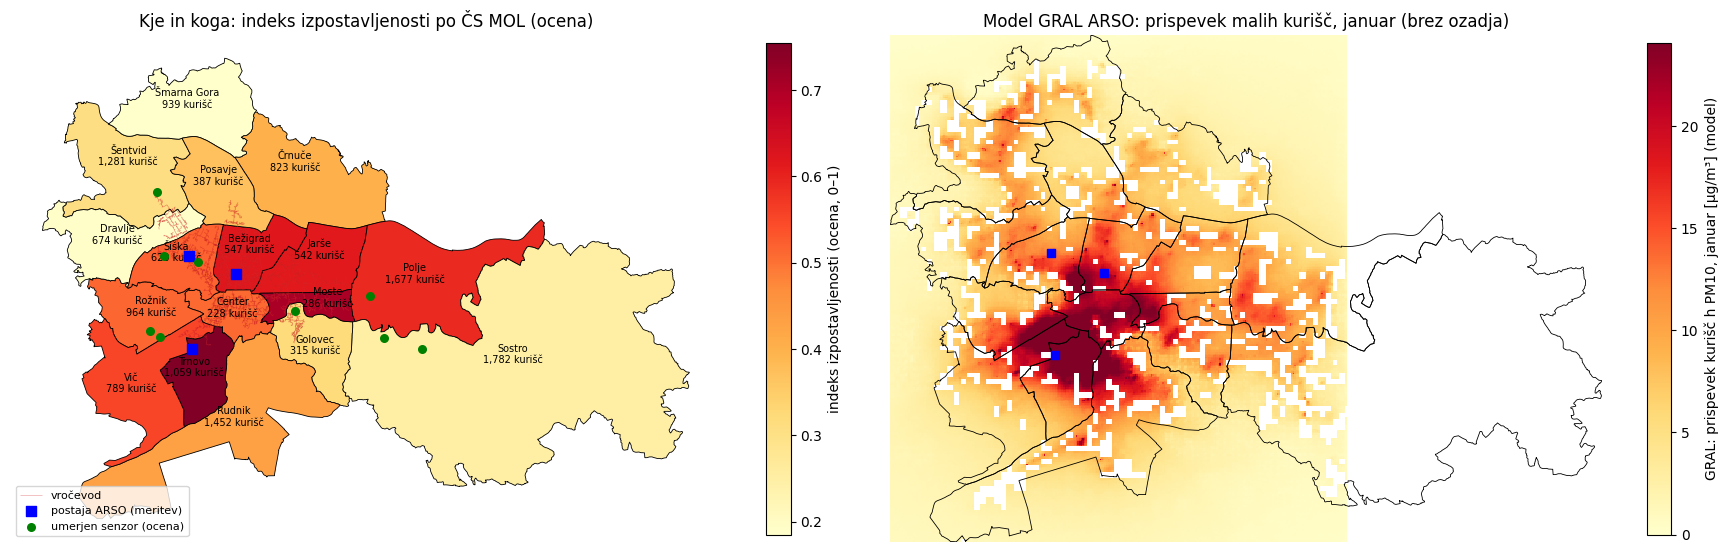

In [10]:
cs_k = cs.set_index("cs_ime").join(k[["indeks", "kurisca_trda_ocena", "pm25_zima_2025_26"]]).reset_index()
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(18, 8.5))
cs_k.plot(column="indeks", cmap="YlOrRd", legend=True, edgecolor="black", linewidth=.6, ax=ax,
          legend_kwds={"label": "indeks izpostavljenosti (ocena, 0–1)", "shrink": .6})
vr.plot(ax=ax, color="tab:red", linewidth=.4, alpha=.5, label="vročevod")
viri[viri.vrsta == "meritev"].plot(ax=ax, color="blue", marker="s", markersize=60, label="postaja ARSO (meritev)", zorder=5)
viri[viri.vrsta != "meritev"].plot(ax=ax, color="green", marker="o", markersize=30, label="umerjen senzor (ocena)", zorder=5)
for _, r in cs_k.iterrows():
    p = r.geometry.representative_point()
    ax.annotate(f"{r.cs_ime}\n{r.kurisca_trda_ocena:,.0f} kurišč", (p.x, p.y), ha="center", fontsize=7)
ax.legend(loc="lower left", fontsize=8); ax.set_axis_off()
ax.set_title("Kje in koga: indeks izpostavljenosti po ČS MOL (ocena)")

with rasterio.open(P/"02_modeli/gral/gral_kurisca_statistika_15m.tif") as r:
    jan = r.read(3, out_shape=(r.height // 4, r.width // 4), resampling=rasterio.enums.Resampling.average)   # 60 m
    ext = (r.bounds.left, r.bounds.right, r.bounds.bottom, r.bounds.top)
    crs_gral = r.crs                                                   # UTM 33N (EPSG:32633), ne D96/TM!
cs_u, viri_u = cs.to_crs(crs_gral), viri.to_crs(crs_gral)              # ostale sloje preslikamo v mrežo GRAL
im = ax2.imshow(np.ma.masked_invalid(jan), extent=ext, cmap="YlOrRd", vmin=0, vmax=np.nanpercentile(jan, 98), interpolation="nearest")
cs_u.boundary.plot(ax=ax2, color="black", linewidth=.6)
viri_u[viri_u.vrsta == "meritev"].plot(ax=ax2, color="blue", marker="s", markersize=40, zorder=5)
ax2.set_xlim(cs_u.total_bounds[[0, 2]]); ax2.set_ylim(cs_u.total_bounds[[1, 3]]); ax2.set_axis_off()
plt.colorbar(im, ax=ax2, shrink=.6, label="GRAL: prispevek kurišč h PM10, januar [µg/m³] (model)")
ax2.set_title("Model GRAL ARSO: prispevek malih kurišč, januar (brez ozadja)")
plt.tight_layout(); plt.show()

## 10. Kaj manjka za "koga"

Paket nima podatkov o **ljudeh** po ČS: starostna struktura (otroci, starejši), vrtci, šole, domovi za starejše, zdravstveni domovi, prebivalstvo po stavbah. Kje bi jih dobili:

- SURS SiStat: prebivalstvo po starosti po naseljih (tabela po naseljih, javna); naselja MOL so v `04_prostor/mol_naselja.geojson`;
- MOL odprti podatki (ArcGIS): vrtci, šole, DSO kot točke;
- OpenStreetMap (Overpass): šole, vrtci, bolnišnice, igrišča;
- Centralni register prebivalstva ni javen; približek je število stanovanj (KN) × povprečna velikost gospodinjstva (SURS).

Z njimi bi indeks postal "izpostavljenost × ranljivost" in bi odgovoril na vprašanje, kje je ukrep najbolj nujen.

In [11]:
out = k.reset_index()[["cs_id", "cs_ime", "povrsina_km2", "stavbe_stan", "stanovanja", "delez_pred_1980", "delez_ob_vrocevodu", "delez_ob_plinovodu",
                        "stavbe_brez_omrezij", "kurisca_trda_ocena", "kurisca_na_km2", "h_nad_dnom_mediana", "delez_pod_30m",
                        "vir", "vrsta", "pm25_zima_2025_26", "vir_km", "indeks",
                        "emisije_kurisca_kg_leto", "emisije_kg_na_km2", "gral_pm10_kurilna", "gral_pm10_januar", "gral_pokritost", "indeks_gral"]]
sr = cs.set_index("cs_ime").geometry.centroid.to_crs(4326)
out["lat"] = out.cs_ime.map(sr.y); out["lon"] = out.cs_ime.map(sr.x)
out.round(4).to_csv("cs_kazalniki.csv", index=False)
print("shranjeno cs_kazalniki.csv:", out.shape)

shranjeno cs_kazalniki.csv: (17, 26)


## Kaj lahko ekipa iz tega naredi

1. **Interaktivna karta tveganja** za občino: sloji (kurišča, lega, meritve) z drsniki za uteži, da odločevalec vidi, kako občutljiva je razvrstitev.
2. **"Koga":** dodati SURS starostno strukturo po naseljih in točke vrtcev/šol/DSO (MOL, OSM) in izračunati število ranljivih ljudi v ČS z visokim indeksom.
3. **Preverjanje ocene kurišč** s podatki o dimnikarskih pregledih ali subvencijah Eko sklada po pošti/naselju, če jih ekipa pridobi.
4. **Globlje z GRAL:** polja 15 m (`02_modeli/gral/`) in urni potek po ČS omogočajo karto "ulica za ulico" (kateri bloki stanovanj so ob virih), dnevni hod prispevka po soseskah in izpostavljenost 318 občutljivih lokacij (`gral_kurisca_obcutljive_lokacije.csv`).
5. **Komunikacija:** za vsako ČS kartica "zakaj je pri vas zrak pozimi slab in kaj pomaga", povezana z zvezkom 07 (scenariji ukrepov).